# Importing packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Preprocessing data

## First data cleaning

In [2]:
df = pd.read_csv('../Data/Thyroid_Diff.csv')
df.head(3)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No


In [3]:
df.rename(columns={'Hx Smoking' : 'Smoking History',
                   'Hx Radiothreapy' : 'Radiotherapy History',
                   'Pathology' : 'Types of cancer',
                   'T' : 'Tumor class',
                   'N' : 'Nodal class',
                   'M': 'Metastasis class',
                   'Stage' : 'Cancer stage'}, inplace=True)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Smoking History       383 non-null    str  
 4   Radiotherapy History  383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Types of cancer       383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  Tumor class           383 non-null    str  
 12  Nodal class           383 non-null    str  
 13  Metastasis class      383 non-null    str  
 14  Cancer stage          383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [5]:
print(df['Adenopathy'].unique())
print(df['Risk'].unique())

<StringArray>
['No', 'Right', 'Extensive', 'Left', 'Bilateral', 'Posterior']
Length: 6, dtype: str
<StringArray>
['Low', 'Intermediate', 'High']
Length: 3, dtype: str


In [6]:
# Ordinal encoding

risk_mapping = {'Low': 0, 'Intermediate': 1, 'High': 2}
df['Risk'] = df['Risk'].map(risk_mapping)

stage_mapping = {'I': 1, 'II': 2, 'III': 3, 'IVA': 4, 'IVB': 5, 'IVC': 6}
df['Cancer stage'] = df['Cancer stage'].map(stage_mapping)

In [7]:
# Binary mapping

df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})

yes_no_cols = ['Smoking', 'Smoking History', 'Radiotherapy History', 'Recurred']
for col in yes_no_cols:
    df[col] = df[col].map({'No': 0, 'Yes': 1})

In [8]:
# One-hot encoding (for multi-class unordered variables)

nominal_columns = [
    'Thyroid Function', 
    'Physical Examination',
    'Adenopathy',
    'Types of cancer', 
    'Focality', 
    'Tumor class', 
    'Nodal class', 
    'Metastasis class'
]

df = pd.get_dummies(df, columns=nominal_columns, drop_first=True)

In [9]:
# Encoding target

le = LabelEncoder()
df['Response'] = le.fit_transform(df['Response'])

In [10]:
df.isnull().sum()

Age                                                 0
Gender                                              0
Smoking                                             0
Smoking History                                     0
Radiotherapy History                                0
Risk                                                0
Cancer stage                                        0
Response                                            0
Recurred                                            0
Thyroid Function_Clinical Hypothyroidism            0
Thyroid Function_Euthyroid                          0
Thyroid Function_Subclinical Hyperthyroidism        0
Thyroid Function_Subclinical Hypothyroidism         0
Physical Examination_Multinodular goiter            0
Physical Examination_Normal                         0
Physical Examination_Single nodular goiter-left     0
Physical Examination_Single nodular goiter-right    0
Adenopathy_Extensive                                0
Adenopathy_Left             

In [11]:
df.duplicated().sum()

np.int64(19)

In [12]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

## First data visualisation

In [13]:
df.describe()

,Age,Gender,Smoking,Smoking History,Radiotherapy History,Risk,Cancer stage,Response,Recurred
count,364.00000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000
mean,41.25000,0.195055,0.134615,0.076923,0.019231,0.456044,1.255495,1.604396,0.296703
std,15.31436,0.396788,0.341782,0.266836,0.137524,0.651966,0.791203,0.931590,0.457433
min,15.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,30.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,38.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
75%,52.00000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.250000,1.000000
max,82.00000,1.000000,1.000000,1.000000,1.000000,2.000000,5.000000,3.000000,1.000000


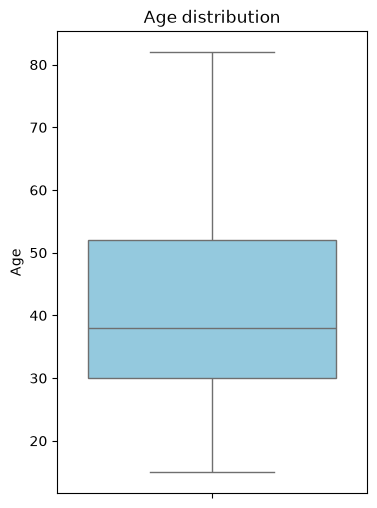

In [14]:
plt.figure(figsize=(4, 6))
plt.title('Age distribution')

sns.boxplot(data=df['Age'], color='skyblue')

plt.show()

1. The people in the sample are quite old (mean around 40, 50% are between 30 and 50 y.o.)
2. Most of them are women (near 80%)
3. There are little clue smoking is linked to tyroid cancer
4. Rate of recovery is large (around 70%)

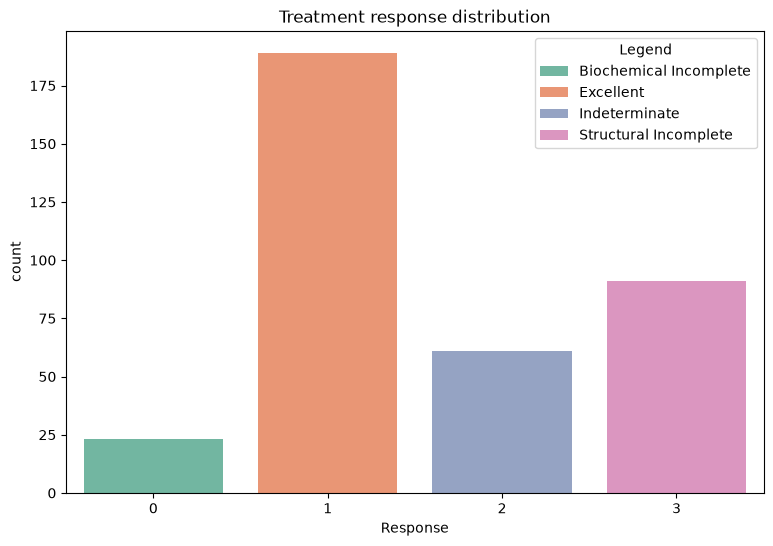

In [15]:
plt.figure(figsize=(9, 6))
plt.title('Treatment response distribution')

sns.countplot(data=df, x='Response', hue = 'Response', palette='Set2')

response_labels = [
    'Biochemical Incomplete',
    'Excellent',
    'Indeterminate',
    'Structural Incomplete'
]
plt.legend(labels = response_labels, title = 'Legend')

plt.show()

Treatment response distribution tells us ~52% of the people get an excellent response to treatment and 48% have some kind of problem with it.
- Biochemical Incomplete (~6%) : Imaging tests show no abnormalities, but tumour markers in the blood remain detectable or abnormal. The disease is still active at a molecular level.
- Indeterminate (~17%) : The clinical or blood test results are inconclusive. This requires longer-term monitoring, but it is not yet clear whether the treatment has failed.
- Structural Incomplete (~25%) : The treatment is unsuitable or has failed. There is still physical and visible evidence of the disease.

## Considerations regarding class imbalances

Out of 383 patients, it appears attempting to predict four separate categories within ``Response``, one of which includes just 23 patients, is bound to fail. We should hence address a binary question regarding treatment options :
1. Excellent response (``Excellent``)
2. Non-excellent response (``Biochemical Incomplete`` + ``Structural incomplete`` + ``Indeterminate``)

## Merging classes, train/test split and scaling

In [16]:
# X and Y separation
X = df.drop(columns=['Response'])
y = df['Response']

In [66]:
# Merging non-excellent classes
y_binary = y.replace(to_replace = [2, 3], value = 0) ;
print((2 or 3) in y_binary.values)

False


In [ ]:
# Test/train split using stratify
X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Scaling
std_scaler = StandardScaler()
std_scaler.set_output(transform="pandas")

X_train = std_scaler.fit_transform(X_train)
X_test = std_scaler.transform(X_test)

## Second data visualisation

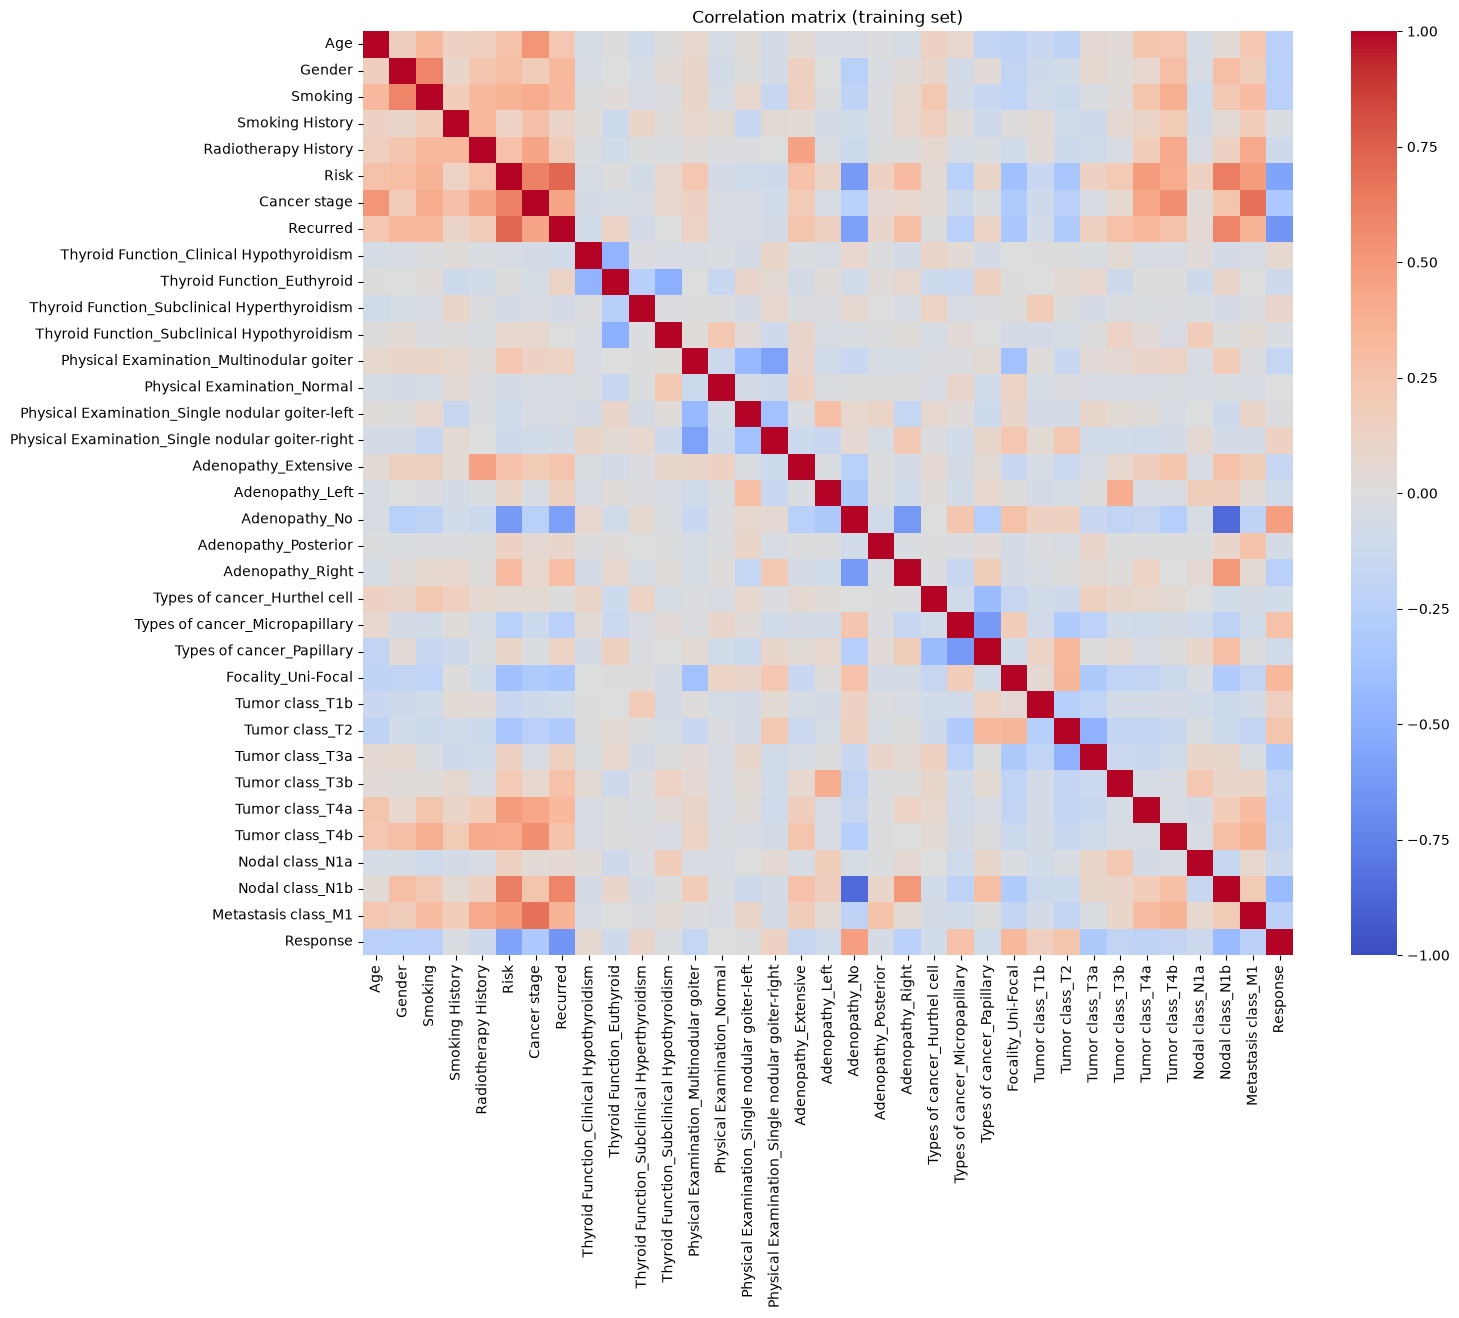

In [32]:
train_data = pd.concat([X_train, y_train], axis = 1)

plt.figure(figsize=(15, 12))

sns.heatmap(train_data.corr(), cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.title('Correlation matrix (training set)')

plt.show()

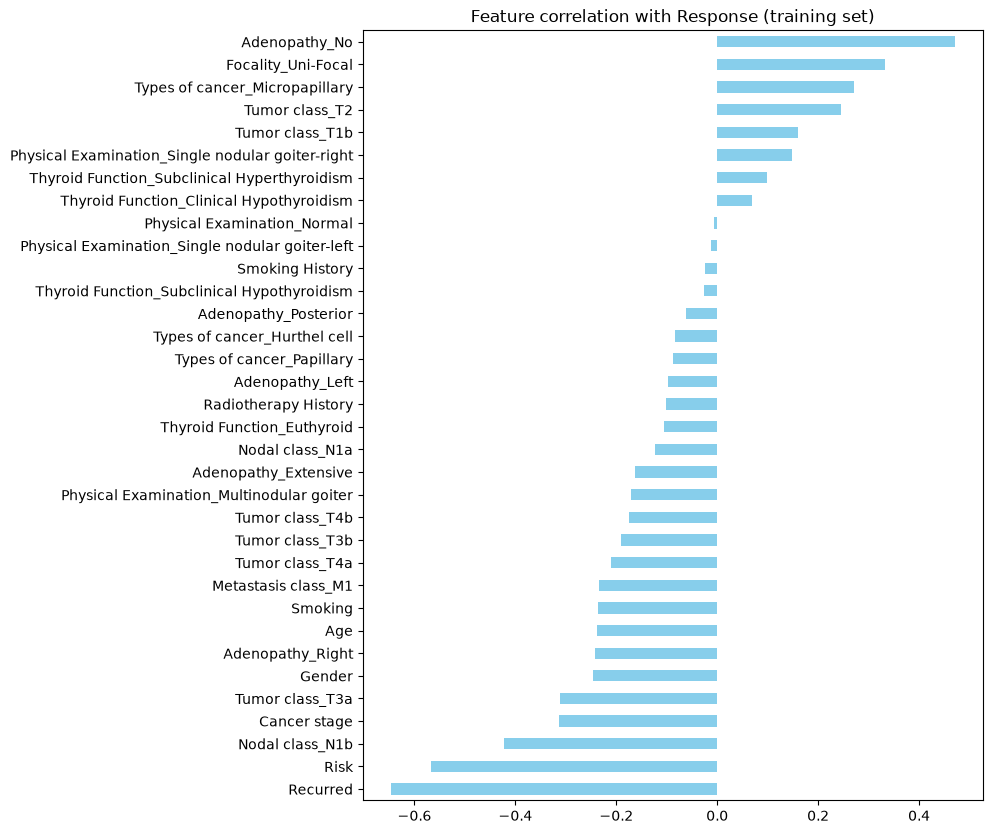

In [33]:
plt.figure(figsize=(8, 10))

train_data.corr()['Response'].sort_values().drop('Response').plot(kind = 'barh', color = 'Skyblue')
plt.title('Feature correlation with Response (training set)')

plt.show()

The clinical response (``Response``) is most strongly associated with recurrence (``Recurred``), risk assessment (``Risk``) and severe lymph node involvement (``Nodal class_N1b``), followed by tumour stage and metastases. 

The absence of lymph node involvement (``Adenopathy_No``) and a unifocal nature (``Focality_Uni-Focal``) emerge as the most decisive favourable markers, showing the strongest negative correlations. Finally, this one-dimensional analysis confirms the non-predictive nature of thyroid function tests and isolated local physical examinations, whose coefficients remain virtually zero, thereby confirming their limited usefulness in modelling this clinical outcome.

Direct implications for the model:
- Multicollinearity and redundancy: ``Smoking`` and ``Smoking History`` are duplicates. If using a linear or logistic model, remove one of the two.   
- Effect of one-hot encoding: the strong negative correlations within the same category (e.g. ``Adenopathy_No`` compared with other types of adenopathy) are mechanical. Consider removing a reference modality (drop_first=True) if decision trees are not being used.

# Model

In addition to the ``Response`` classes merging, we may also need to consider the following solutions to fix the class imbalances :

1. Ponderate the model using ``class_weight='balanced'``
2. Choosing any evaluation metrics not sensible to class imbalances, such as confusion matrice or F1-score

## Linear SVC model

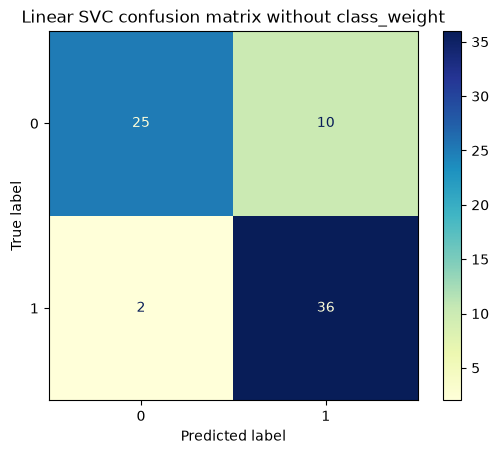

In [39]:
# Model
lsvc = LinearSVC(random_state=0, max_iter=5000) # may nedd to change max_iter

# Training
lsvc.fit(X_train, y_train)

# Prediction
y_pred = lsvc.predict(X_test)

# Graph
lsvc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
lsvc_cm.plot(cmap = 'YlGnBu')
plt.title('Linear SVC confusion matrix without class_weight')
plt.show()

In [37]:
(36+25)/73

0.8356164383561644

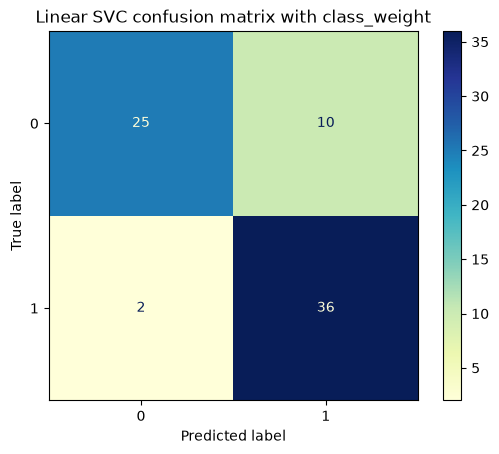

In [42]:
# Model
lsvc = LinearSVC(class_weight='balanced', random_state=0, max_iter=5000) # may nedd to change max_iter

# Training
lsvc.fit(X_train, y_train)

# Prediction
y_pred = lsvc.predict(X_test)

# Graph
lsvc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
lsvc_cm.plot(cmap = 'YlGnBu')
plt.title('Linear SVC confusion matrix with class_weight')
plt.show()

In [41]:
(36+25)/73

0.8356164383561644

## Kneighbours classifier

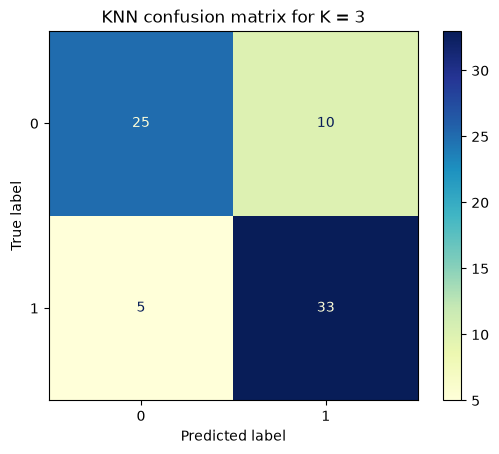

In [43]:
# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Graph
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 3')
plt.show()

In [44]:
(33+25)/73

0.7945205479452054

The results look quite the same as for linear SVC for now. We may need to look for a better $K$.

In [46]:
for K in range(1,25) :

    # Train a k-NN classifier
    knn = KNeighborsClassifier(n_neighbors = K)
    knn.fit(X_train, y_train)

    # Prediction
    y_pred = knn.predict(X_test)

    # Evaluation
    trace = np.trace(confusion_matrix(y_test, y_pred))
    print(f'Trace of the confusion matrix is {trace} for K = {K}.')

Trace of the confusion matrix is 53 for K = 1.
Trace of the confusion matrix is 51 for K = 2.
Trace of the confusion matrix is 58 for K = 3.
Trace of the confusion matrix is 54 for K = 4.
Trace of the confusion matrix is 58 for K = 5.
Trace of the confusion matrix is 56 for K = 6.
Trace of the confusion matrix is 58 for K = 7.
Trace of the confusion matrix is 58 for K = 8.
Trace of the confusion matrix is 56 for K = 9.
Trace of the confusion matrix is 57 for K = 10.
Trace of the confusion matrix is 58 for K = 11.
Trace of the confusion matrix is 58 for K = 12.
Trace of the confusion matrix is 58 for K = 13.
Trace of the confusion matrix is 59 for K = 14.
Trace of the confusion matrix is 59 for K = 15.
Trace of the confusion matrix is 58 for K = 16.
Trace of the confusion matrix is 59 for K = 17.
Trace of the confusion matrix is 59 for K = 18.
Trace of the confusion matrix is 58 for K = 19.
Trace of the confusion matrix is 57 for K = 20.
Trace of the confusion matrix is 59 for K = 21.
T

It seems the best confusion matrix we got was for $K = 14$.

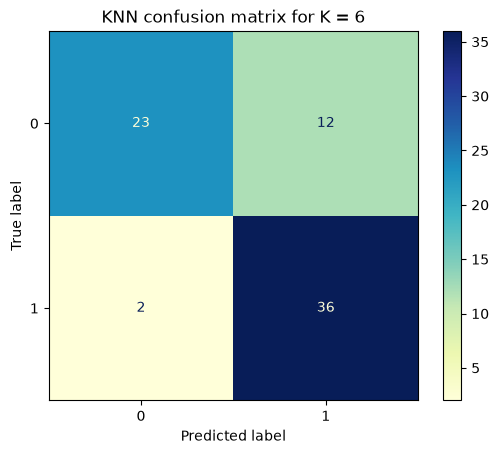

In [ ]:
K = 14

# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors = K)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Graph
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 14')
plt.show()

In [49]:
(36+23) / 73

0.8082191780821918

None of the $K$ parameters gave us a better result than linear SVC (sum of trace was 0.83).

## SVC model

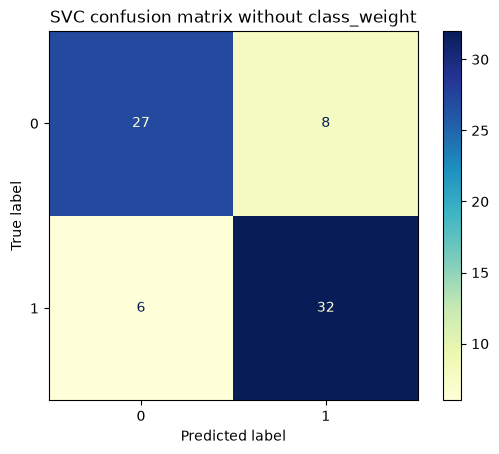

In [52]:
# Model
svc = SVC(random_state=0, max_iter=5000)

# Training
svc.fit(X_train, y_train)

# Prediction
y_pred = svc.predict(X_test)

# Graph
svc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
svc_cm.plot(cmap = 'YlGnBu')
plt.title('SVC confusion matrix without class_weight')
plt.show()

In [53]:
(32+27) / 73

0.8082191780821918

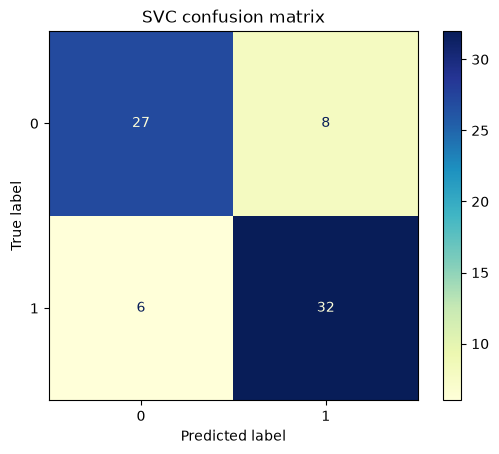

In [54]:
# Model
svc = SVC(class_weight='balanced', random_state=0, max_iter=5000)

# Training
svc.fit(X_train, y_train)

# Prediction
y_pred = svc.predict(X_test)

# Graph
svc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
svc_cm.plot(cmap = 'YlGnBu')
plt.title('SVC confusion matrix')
plt.show()

In [55]:
(32+27) / 73

0.8082191780821918

SVC did slightly worse than linear SVC in terms of trace score. Still, the amount of false classification for label 0 and 1 almost are the same for this model.

## Random Forest Classifier

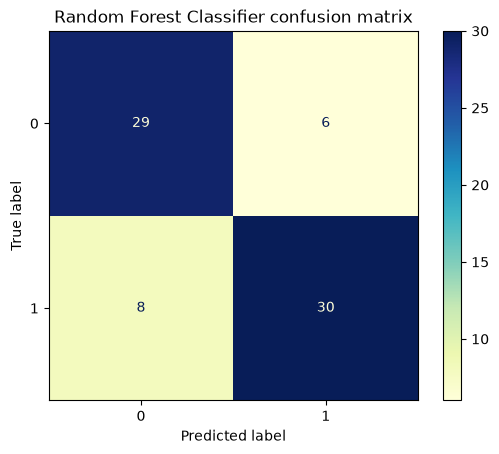

In [57]:
# Model
rfc = RandomForestClassifier(random_state=42)

# Training
rfc.fit(X_train, y_train)

# Prediction
y_pred = rfc.predict(X_test)

# Graph
rfc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
rfc_cm.plot(cmap = 'YlGnBu')
plt.title('Random Forest Classifier confusion matrix')
plt.show()

In [59]:
(30+29) / 73

0.8082191780821918

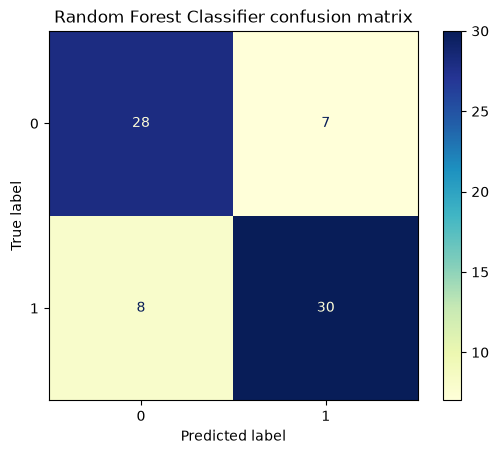

In [58]:
# Model
rfc = RandomForestClassifier(class_weight='balanced', random_state=42)

# Training
rfc.fit(X_train, y_train)

# Prediction
y_pred = rfc.predict(X_test)

# Graph
rfc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
rfc_cm.plot(cmap = 'YlGnBu')
plt.title('Random Forest Classifier confusion matrix')
plt.show()

In [60]:
(30+28) / 73

0.7945205479452054

It looks like Random Forest gave us about the same results as SVC.

## XGBoost